In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report


# 1. Load Dataset
df = pd.read_csv(
    "/content/drive/MyDrive/ML_LAB/amazon.txt",
    sep="\t",
    header=None,
    names=["message", "label"]
)

df.head()

,message,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


Accuracy: 0.825

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.77      0.80        93
           1       0.82      0.87      0.84       107

    accuracy                           0.82       200
   macro avg       0.83      0.82      0.82       200
weighted avg       0.83      0.82      0.82       200



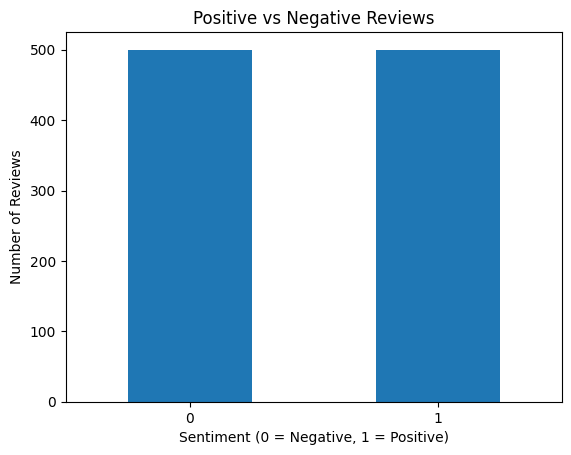

In [8]:

# 2. Clean Text
df["message"] = df["message"].str.lower()
df["message"] = df["message"].str.replace(
    r"[^a-z\s]", "", regex=True
)

# 3. Separate Input and Output
X = df["message"]
y = df["label"]

# 4. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Convert Text into TF-IDF Features
tfidf = TfidfVectorizer(stop_words="english")

X_train = tfidf.fit_transform(X_train)
X_test = tfidf.transform(X_test)

# 6. Train Naive Bayes Model
model = MultinomialNB()
model.fit(X_train, y_train)

# 7. Make Predictions
y_pred = model.predict(X_test)

# 8. Evaluate Model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 9. Plot Review Categories
df["label"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Sentiment (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")
plt.title("Positive vs Negative Reviews")
plt.xticks(rotation=0)
plt.show()
